# Speed Prediction — 파생/추가 피처 빠른 테스트 (LightGBM)

**목적**: `11_speed_model_baseline.ipynb`의 LightGBM 결과를 기준점으로 두고, 파생 피처와 신규 외부 피처를 추가했을 때 실제로 개선되는지 **LightGBM 하나로만** 빠르게 확인합니다.

**핵심 전제**: 여기서 만드는 피처들은 전부 **미관측 링크(29.25%)에도 쓸 수 있는 범용 피처** 후보를 찾는 작업입니다 — 관측 링크는 자기 자신의 과거 속도 이력(Model A 방식)을 쓰면 되므로 이 노트북의 범위가 아닙니다.

**버전 변경 이력**
- 1차: 버스전용차로를 30% 겹침 기준 boolean으로 추가 (gain 0.17%)
- 2차: 버스전용차로를 겹침 비율(연속값)로 바꾸고, **추정교통량**(`TrafficVolume(LINK) (1).xlsx`, 2024년 평일 기준 AADT+시간대별)을 `ITS LINK ID` 매칭(콤마로 묶인 셀 펼쳐서)으로 추가
- 3차(이번): **인접 실측 이웃 속도** 추가 — 도로망 위상(`F_NODE`/`T_NODE`)으로 1홉 이웃 중 관측된 링크들의 그 시각 실제 속도 평균. 예측값이 아니라 실측값이라 순환 의존 문제 없음(사전 검증: 관측 링크 97.0%가 관측 이웃 보유, 상관계수 0.685)

**비교 기준점(재실행 없이 인용)**

| model | rmse | mae | r2 |
| --- | --- | --- | --- |
| LightGBM (11번, 원본 피처) | 7.653 | 5.765 | 0.610 |
| LightGBM (1차: +파생/버스전용차로 boolean) | 7.629 | 5.747 | 0.613 |
| LightGBM (2차: +비율/교통량) | 7.508 | 5.659 | 0.625 |

**캐싱**: 원본 CSV 로딩+공간조인 결과만 `data/interim/nb12_feature_cache_v2.parquet`에 캐싱합니다(버스전용차로/교통량 스키마는 안 바뀌어서 기존 캐시 재사용). 인접 이웃 속도는 캐시 이후 단계에서 매번 새로 계산합니다(희소행렬 연산이라 몇 초면 끝남).

In [1]:
import gc
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_dem_weather_merged.csv"
SEOUL_LINK_SHP = INTERIM_DIR / "seoul_link.shp"
BUS_LANE_SHP = RAW_DIR / "traffic" / "A058_L_20260213" / "A058_L" / "A058_L.shp"
TRAFFIC_VOLUME_XLSX = RAW_DIR / "traffic" / "TrafficVolume(LINK) (1).xlsx"
CACHE_PATH = INTERIM_DIR / "nb12_feature_cache_v2.parquet"

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
COLOR_RMSE = "#2a78d6"   # dataviz 팔레트 slot 1 blue
COLOR_MAE = "#eb6834"    # dataviz 팔레트 slot 2 orange
COLOR_SEQ = "#3987e5"

BASELINE_11 = {"model": "LightGBM (11번, 원본 피처)", "rmse": 7.652966670997528, "mae": 5.764899686592482, "r2": 0.6101212805788272}
BASELINE_V1 = {"model": "LightGBM (1차: +파생/버스전용차로 boolean)", "rmse": 7.629313, "mae": 5.747021, "r2": 0.612528}
BASELINE_V2 = {"model": "LightGBM (2차: +비율/교통량)", "rmse": 7.508456, "mae": 5.658695, "r2": 0.624706}


## 1. 버스전용차로 겹침 비율 (연속값으로 개선)

1차 시도에서 30% 겹침 여부만 boolean으로 넣었더니 gain 기여도가 0.17%로 낮았습니다. 겹침 비율 자체(0~1 연속값)를 그대로 넣으면 "얼마나 겹치는지" 정보가 보존되어 트리가 더 세밀한 분기를 찾을 여지가 생깁니다.

In [2]:
seoul_link = gpd.read_file(SEOUL_LINK_SHP)
bus = gpd.read_file(BUS_LANE_SHP).to_crs(seoul_link.crs)

bus_buffer = bus.buffer(8).union_all()
overlap_len = seoul_link.geometry.intersection(bus_buffer).length
overlap_ratio = (overlap_len / seoul_link.geometry.length).clip(upper=1).fillna(0)

bus_lane_lookup = pd.DataFrame({
    "LINK_ID": seoul_link["LINK_ID"].astype(str),
    "bus_lane_ratio": overlap_ratio.astype("float32"),
})
print("겹침 비율 > 0인 링크 수:", (bus_lane_lookup["bus_lane_ratio"] > 0).sum(), "/", len(bus_lane_lookup))
print(bus_lane_lookup["bus_lane_ratio"].describe())


겹침 비율 > 0인 링크 수: 5011 / 63548
count    63548.000000
mean         0.049993
std          0.202863
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: bus_lane_ratio, dtype: float64


## 2. 추정교통량 (신규)

`TrafficVolume(LINK) (1).xlsx`는 Level 5.5(주요도로망) 링크 단위 2024년 평일 추정교통량입니다. `ITS LINK ID` 컬럼이 우리 `LINK_ID`와 같은 체계지만, 굵은 구간 하나가 여러 세부 링크를 포함해서 콤마로 여러 ID가 묶인 셀이 있습니다 — 펼쳐서(explode) 매칭합니다.

시간대별 컬럼은 `0~1시`~`23~24시` 24개입니다. 우리 `시간코드`가 1~24 값이라, **시간코드 i = i번째 시간대 버킷(즉 시간코드 1 = 0~1시, 시간코드 24 = 23~24시)**으로 가정해 매칭합니다(공식 문서로 확인된 건 아니라 가정임을 표시해둡니다).

In [3]:
tv_col_names = [
    "LEVEL55_LINK_ID", "ITS_LINK_ID", "road_rank_tv", "road_name_tv", "region_tv",
    "length_km_tv", "lanes_tv", "aadt",
] + [f"vol_h{h}" for h in range(1, 25)]

tv = pd.read_excel(TRAFFIC_VOLUME_XLSX, sheet_name="Sheet0", header=6, skiprows=[7])
tv.columns = tv_col_names

tv["its_id_list"] = tv["ITS_LINK_ID"].astype(str).str.split(",")
tv_exp = tv.explode("its_id_list")
tv_exp["LINK_ID"] = tv_exp["its_id_list"].str.strip()
tv_exp = tv_exp[tv_exp["LINK_ID"] != "0"]  # 대응하는 ITS 링크가 없는 자리표시자(0) 제거

# 콤마로 묶인 구간이 겹쳐서 같은 LINK_ID가 여러 5.5 LINK ID 그룹에 속할 수 있어 평균으로 합침
aadt_lookup = tv_exp.groupby("LINK_ID", as_index=False)["aadt"].mean().rename(columns={"aadt": "traffic_volume_aadt"})

hourly_cols = [f"vol_h{h}" for h in range(1, 25)]
tv_long = tv_exp.melt(id_vars="LINK_ID", value_vars=hourly_cols, var_name="hour_col", value_name="traffic_volume_hourly")
tv_long["시간코드"] = tv_long["hour_col"].str.replace("vol_h", "", regex=False).astype("float32")
tv_long = tv_long.groupby(["LINK_ID", "시간코드"], as_index=False)["traffic_volume_hourly"].mean()

print("AADT 매칭 링크 수:", aadt_lookup["LINK_ID"].nunique())
print("시간대별 교통량 행 수:", len(tv_long), "(링크 수 x 24시간)")


C:\Users\ejjun\AppData\Roaming\Python\Python313\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


AADT 매칭 링크 수: 18164
시간대별 교통량 행 수: 435936 (링크 수 x 24시간)


## 3. 데이터 로드 (+ 캐싱)

In [4]:
NUMERIC_COLS = [
    "LANES", "MAX_SPD", "LENGTH", "시간코드",
    "elev_start_m", "elev_mid_m", "elev_end_m", "elev_mean_m", "elev_min_m", "elev_max_m", "elev_delta_m",
    "slope_pct", "abs_slope_pct", "precip_mm",
]
CATEGORICAL_COLS = [
    "ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
    "REST_VEH", "REST_W", "REST_H", "C-ITS",
]
# 결측이 정상인 컬럼(전체 매칭 안 됨) — NUMERIC_COLS의 dropna 대상에서 제외하고 LightGBM 기본 결측치 처리에 맡김
SPARSE_NUMERIC_COLS = ["traffic_volume_aadt", "traffic_volume_hourly"]
TARGET = "평균속도"

if CACHE_PATH.exists():
    df = pd.read_parquet(CACHE_PATH)
    print("캐시에서 로드:", CACHE_PATH)
else:
    usecols = NUMERIC_COLS + CATEGORICAL_COLS + [TARGET, "LINK_ID", "기준일"]
    dtype_map = {col: str for col in CATEGORICAL_COLS}
    dtype_map["LINK_ID"] = str
    dtype_map["기준일"] = str

    df = pd.read_csv(INPUT_PATH, usecols=usecols, dtype=dtype_map, encoding="utf-8-sig")

    for col in NUMERIC_COLS + [TARGET]:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")

    df = df.merge(bus_lane_lookup, on="LINK_ID", how="left")
    df["bus_lane_ratio"] = df["bus_lane_ratio"].fillna(0).astype("float32")

    df = df.merge(aadt_lookup, on="LINK_ID", how="left")
    df = df.merge(tv_long, on=["LINK_ID", "시간코드"], how="left")

    RENAME_MAP = {"C-ITS": "c_its"}
    df = df.rename(columns=RENAME_MAP)
    CATEGORICAL_COLS = [RENAME_MAP.get(c, c) for c in CATEGORICAL_COLS]

    df = df.dropna(subset=[TARGET] + NUMERIC_COLS)
    df.to_parquet(CACHE_PATH)
    print("새로 만들어서 캐시 저장:", CACHE_PATH)

CATEGORICAL_COLS = [c if c != "C-ITS" else "c_its" for c in CATEGORICAL_COLS]
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype("category")

print("행 수:", len(df), "| 컬럼 수:", df.shape[1])
print("메모리 사용량(MB):", round(df.memory_usage(deep=True).sum() / 1e6, 1))
print()
print("traffic_volume_hourly 결측 비율:", round(df["traffic_volume_hourly"].isna().mean() * 100, 1), "%")
print("traffic_volume_aadt 결측 비율:", round(df["traffic_volume_aadt"].isna().mean() * 100, 1), "%")
df.head()


캐시에서 로드: C:\Users\ejjun\Desktop\seoul-eco-routing\data\interim\nb12_feature_cache_v2.parquet


행 수: 15094335 | 컬럼 수: 29
메모리 사용량(MB): 1856.6

traffic_volume_hourly 결측 비율: 60.7 %
traffic_volume_aadt 결측 비율: 60.7 %


,LINK_ID,기준일,시간코드,평균속도,LANES,ROAD_RANK,ROAD_TYPE,ROAD_USE,MULTI_LINK,CONNECT,...,elev_mean_m,elev_min_m,elev_max_m,elev_delta_m,slope_pct,abs_slope_pct,precip_mm,bus_lane_ratio,traffic_volume_aadt,traffic_volume_hourly
0,1000000301,20260707,1.0,13.166667,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,398.0
1,1000000301,20260707,2.0,16.250000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,317.0
2,1000000301,20260707,3.0,14.000000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,213.0
3,1000000301,20260707,4.0,15.000000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,180.0
4,1000000301,20260707,5.0,15.250000,2.0,103,0,0,1,0,...,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0,0.785023,19985.0,255.0


## 4. 파생 피처 생성 (요일/주말/시간 순환 인코딩)

캐시 이후 단계라 로직을 바꿔도 캐시 무효화가 필요 없습니다.

In [5]:
df["_date"] = pd.to_datetime(df["기준일"], format="%Y%m%d")
df["dow"] = df["_date"].dt.weekday.astype("category")
df["is_weekend"] = (df["_date"].dt.weekday >= 5).astype("int8")

hour = df["시간코드"].astype("float32")
df["hour_sin"] = np.sin(2 * np.pi * hour / 24).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * hour / 24).astype("float32")

df = df.drop(columns=["_date"])


## 5. 인접 실측 이웃 속도 (신규)

**목적**: 지금 만드는 피처들은 전부 "미관측 링크에도 쓸 수 있는 범용 피처" 후보를 찾는 작업입니다(관측 링크 자체는 나중에 Model A처럼 자기 이력을 쓰면 되니 여기서는 다루지 않습니다). 이번엔 "이 링크와 도로망으로 맞닿은 링크가 **그 시각에 실제로 관측된 값**"을 피처로 추가합니다(이웃의 예측값이 아니라 실측값 — 순환 의존 문제 없음).

사전 검증(별도 확인): 관측 링크의 97.0%가 관측된 1홉 이웃을 갖고 있고, 자기 실제속도와 이웃의 실제속도 상관계수는 0.685였습니다. 미관측 링크 기준으로는 75.3%가 1홉 안에 실측 이웃을 갖습니다.

**계산 방식**: `F_NODE`/`T_NODE` 위상으로 1홉 인접 그래프를 만들고, 링크 x 시간대(LINK_ID x tm) 속도 행렬에 희소 인접행렬을 곱해 "1홉 관측 이웃들의 그 시각 평균 실제속도"를 한 번에 계산합니다(결측 이웃은 자동으로 평균에서 제외). 1홉 안에 관측 이웃이 없는 링크는 NaN으로 남겨 LightGBM 기본 결측 처리에 맡깁니다.

**주의**: 여기서는 무작위 분할로 "이 피처에 신호가 있는지"만 빠르게 봅니다. "미관측 링크에서 실제로 얼마나 도움되는지"를 정직하게 보려면 나중에 section/link 단위 GroupKFold(Model B 평가 방식)로 다시 확인해야 합니다.

In [6]:
import geopandas as gpd
from collections import defaultdict
from scipy.sparse import csr_matrix

seoul_link_topo = gpd.read_file(SEOUL_LINK_SHP)[["LINK_ID", "F_NODE", "T_NODE"]]
seoul_link_topo["LINK_ID"] = seoul_link_topo["LINK_ID"].astype(str)

node_links = defaultdict(set)
for r in seoul_link_topo.itertuples(index=False):
    node_links[r.F_NODE].add(r.LINK_ID)
    node_links[r.T_NODE].add(r.LINK_ID)
link_neighbors = defaultdict(set)
for node, links in node_links.items():
    for l in links:
        link_neighbors[l].update(links - {l})

df["tm_key"] = df["기준일"].astype(str) + "_" + df["시간코드"].astype(int).astype(str)

link_ids_sorted = np.sort(df["LINK_ID"].unique())
link_idx = {l: i for i, l in enumerate(link_ids_sorted)}
observed_set = set(link_ids_sorted)
n_links = len(link_ids_sorted)

rows_idx, cols_idx = [], []
for l in link_ids_sorted:
    i = link_idx[l]
    for n in link_neighbors.get(l, ()):
        if n in observed_set:
            rows_idx.append(i)
            cols_idx.append(link_idx[n])
A = csr_matrix((np.ones(len(rows_idx), dtype="float32"), (rows_idx, cols_idx)), shape=(n_links, n_links))
print("인접(관측-관측) 엣지 수:", len(rows_idx), "| 1홉 관측 이웃이 0개인 링크:",
      (np.asarray(A.sum(axis=1)).ravel() == 0).sum())

speed_wide = df.pivot_table(index="LINK_ID", columns="tm_key", values=TARGET, aggfunc="mean")
speed_wide = speed_wide.reindex(link_ids_sorted)

valid = (~speed_wide.isna()).to_numpy(dtype="float32")
filled = np.nan_to_num(speed_wide.to_numpy(dtype="float32"), nan=0.0)

numerator = A @ filled
denom = A @ valid
with np.errstate(invalid="ignore", divide="ignore"):
    neighbor_mean = numerator / denom
neighbor_mean[denom == 0] = np.nan

tm_columns = list(speed_wide.columns)  # 9번 섹션(폴드별 재계산)에서 재사용

neighbor_long = pd.DataFrame(neighbor_mean, index=speed_wide.index, columns=speed_wide.columns) \
    .reset_index().melt(id_vars="LINK_ID", var_name="tm_key", value_name="nearest_obs_neighbor_speed")
df = df.merge(neighbor_long, on=["LINK_ID", "tm_key"], how="left")
df = df.drop(columns=["tm_key"])

# filled/valid(링크x시간 실측 행렬)와 link_neighbors/link_idx는 9번 섹션(GroupKFold, 폴드별 이웃
# 재계산)에서 다시 쓰므로 지우지 않음 — speed_wide/A(전체 기준)와 중간 계산값만 정리
del speed_wide, numerator, denom, neighbor_mean, neighbor_long
gc.collect()

print("nearest_obs_neighbor_speed 결측 비율:", round(df["nearest_obs_neighbor_speed"].isna().mean() * 100, 1), "%")
print(df["nearest_obs_neighbor_speed"].describe())


인접(관측-관측) 엣지 수: 145764 | 1홉 관측 이웃이 0개인 링크: 1334


nearest_obs_neighbor_speed 결측 비율: 3.0 %


count    1.464761e+07
mean     2.300422e+01
std      1.056611e+01
min      1.000000e+00
25%      1.662500e+01
50%      2.064583e+01
75%      2.613750e+01
max      1.079375e+02
Name: nearest_obs_neighbor_speed, dtype: float64


In [7]:
SPARSE_NUMERIC_COLS = SPARSE_NUMERIC_COLS + ["nearest_obs_neighbor_speed"]
DERIVED_COLS = ["dow", "is_weekend", "hour_sin", "hour_cos", "bus_lane_ratio"] + SPARSE_NUMERIC_COLS
df[DERIVED_COLS].describe(include="all")


,dow,is_weekend,hour_sin,hour_cos,bus_lane_ratio,traffic_volume_aadt,traffic_volume_hourly,nearest_obs_neighbor_speed
count,15094335.0,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,5.938480e+06,5.938480e+06,1.464761e+07
unique,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,2157217.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2.857848e-01,-2.138451e-05,7.420300e-06,6.608189e-02,2.066972e+04,8.612402e+02,2.300422e+01
std,NaN,4.517874e-01,7.071058e-01,7.071078e-01,2.317023e-01,1.518205e+04,7.655930e+02,1.056611e+01
min,NaN,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,1.093000e+03,0.000000e+00,1.000000e+00
25%,NaN,0.000000e+00,-7.071067e-01,-7.071068e-01,0.000000e+00,1.115400e+04,3.570000e+02,1.662500e+01
50%,NaN,0.000000e+00,-8.742278e-08,1.192488e-08,0.000000e+00,1.748900e+04,6.600000e+02,2.064583e+01
75%,NaN,1.000000e+00,7.071068e-01,7.071070e-01,0.000000e+00,2.567400e+04,1.144000e+03,2.613750e+01


## 6. Train/Test 분할

11번과 동일하게 `random_state=42`, `test_size=0.2` 무작위 분할입니다.

In [8]:
FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS + DERIVED_COLS
X = df[FEATURE_COLS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("train/test 행 수:", len(X_train), len(X_test))


train/test 행 수: 12075468 3018867


## 7. LightGBM 학습

베이스라인과 동일한 하이퍼파라미터를 씁니다.

In [9]:
def evaluate(y_true, y_pred, name):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"model": name, "rmse": rmse, "mae": mae, "r2": r2}


lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    verbosity=-1,
)
lgb_model.fit(X_train, y_train, categorical_feature=CATEGORICAL_COLS + ["dow"])
pred = lgb_model.predict(X_test)

results_df = pd.DataFrame([BASELINE_11, BASELINE_V1, BASELINE_V2, evaluate(y_test, pred, "LightGBM (3차: +인접 실측 이웃 속도)")])
results_df


,model,rmse,mae,r2
0,"LightGBM (11번, 원본 피처)",7.652967,5.764900,0.610121
1,LightGBM (1차: +파생/버스전용차로 boolean),7.629313,5.747021,0.612528
2,LightGBM (2차: +비율/교통량),7.508456,5.658695,0.624706
3,LightGBM (3차: +인접 실측 이웃 속도),6.197259,4.461506,0.744336


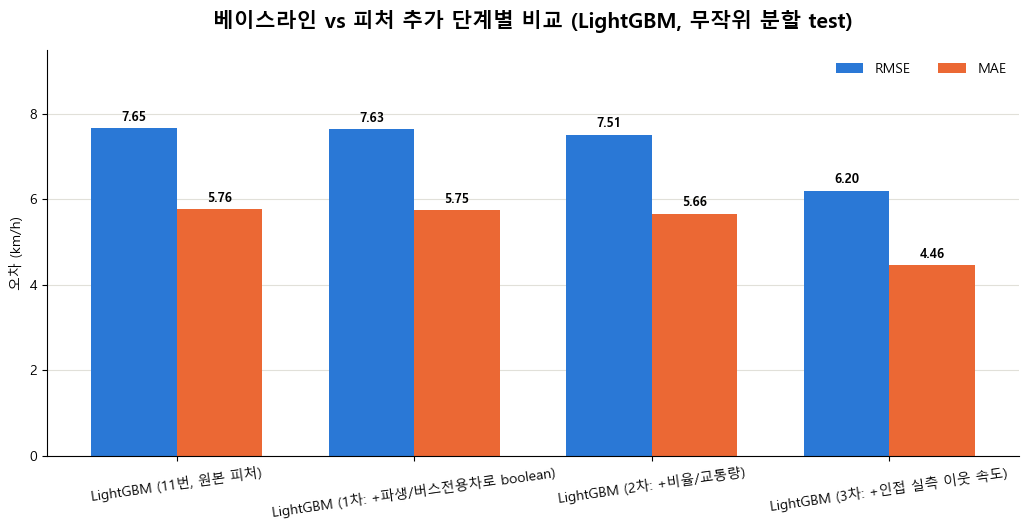

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\04_derived_features_comparison_v2.png


In [10]:
labels = results_df["model"].tolist()
x = range(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.bar([i - width / 2 for i in x], results_df["rmse"], width, label="RMSE", color=COLOR_RMSE)
ax.bar([i + width / 2 for i in x], results_df["mae"], width, label="MAE", color=COLOR_MAE)
ax.set_xticks(list(x), labels, rotation=8)
ax.set_title("베이스라인 vs 피처 추가 단계별 비교 (LightGBM, 무작위 분할 test)", fontsize=15, fontweight="bold", pad=16)
ax.set_ylabel("오차 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")

for patch in ax.patches:
    height = patch.get_height()
    ax.text(patch.get_x() + patch.get_width() / 2, height + 0.1, f"{height:.2f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.18)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "04_derived_features_comparison_v2.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "04_derived_features_comparison_v2.png")


## 8. 피처 중요도 — 신규/파생 피처 순위

In [11]:
importance = pd.DataFrame({
    "feature": lgb_model.feature_name_,
    "gain": lgb_model.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
importance["gain_share"] = importance["gain"] / importance["gain"].sum()
importance["is_new"] = importance["feature"].isin(DERIVED_COLS)

print("=== 신규/파생 피처 순위 ===")
print(importance[importance["is_new"]].to_string(index=False))
print()
print("=== 전체 상위 15개 ===")
print(importance.head(15)[["feature", "gain_share"]].round(4).to_string(index=False))


=== 신규/파생 피처 순위 ===
                   feature         gain  gain_share  is_new
nearest_obs_neighbor_speed 1.149447e+10    0.830473    True
       traffic_volume_aadt 1.789995e+08    0.012933    True
            bus_lane_ratio 3.754791e+07    0.002713    True
     traffic_volume_hourly 1.770283e+07    0.001279    True
                  hour_sin 8.848964e+06    0.000639    True
                  hour_cos 4.697142e+06    0.000339    True
                       dow 2.266535e+06    0.000164    True
                is_weekend 8.201234e+05    0.000059    True

=== 전체 상위 15개 ===
                   feature  gain_share
nearest_obs_neighbor_speed      0.8305
                   MAX_SPD      0.0547
                    LENGTH      0.0179
       traffic_volume_aadt      0.0129
                     LANES      0.0129
                 ROAD_TYPE      0.0113
                    REST_H      0.0068
                      시간코드      0.0051
              elev_start_m      0.0045
                 ROAD_RANK     

## 요약

In [12]:
prev = results_df.iloc[2]
curr = results_df.iloc[3]
delta_rmse = prev["rmse"] - curr["rmse"]
delta_mae = prev["mae"] - curr["mae"]

print("=== 2차(비율+교통량) 대비 3차(+인접 실측 이웃 속도) 변화 ===")
print(f"RMSE: {prev['rmse']:.3f} -> {curr['rmse']:.3f} (Δ{delta_rmse:+.3f})")
print(f"MAE:  {prev['mae']:.3f} -> {curr['mae']:.3f} (Δ{delta_mae:+.3f})")
print(f"R²:   {prev['r2']:.3f} -> {curr['r2']:.3f}")
print()
print("=== 11번 베이스라인 대비 누적 변화 ===")
base = results_df.iloc[0]
print(f"RMSE: {base['rmse']:.3f} -> {curr['rmse']:.3f} (Δ{base['rmse']-curr['rmse']:+.3f})")
print(f"MAE:  {base['mae']:.3f} -> {curr['mae']:.3f} (Δ{base['mae']-curr['mae']:+.3f})")


=== 2차(비율+교통량) 대비 3차(+인접 실측 이웃 속도) 변화 ===
RMSE: 7.508 -> 6.197 (Δ+1.311)
MAE:  5.659 -> 4.462 (Δ+1.197)
R²:   0.625 -> 0.744

=== 11번 베이스라인 대비 누적 변화 ===
RMSE: 7.653 -> 6.197 (Δ+1.456)
MAE:  5.765 -> 4.462 (Δ+1.303)


이 노트북은 파생/추가 피처가 도움이 되는지만 빠르게 확인하는 용도입니다(LightGBM 1개, 원본 하이퍼파라미터 그대로). 최종 파이프라인 반영 여부, 3개 모델 재비교, 하이퍼파라미터 튜닝은 여기서 개선 효과가 확인된 뒤 별도로 진행합니다.

캐시(`data/interim/nb12_feature_cache_v2.parquet`)는 이 노트북 전용 임시 파일입니다 — `data/README.md`의 공식 파이프라인 산출물 목록에는 포함되지 않습니다.

**남은 가정/한계**: 추정교통량의 시간대 매칭(시간코드 1=0~1시)은 공식 문서로 확인된 게 아니라 순서 기반 가정입니다. 또한 이 데이터는 2024년 평일 기준이라 2026년 7월(주말 포함) 관측과 시점·요일 구성이 다릅니다.

## 9. 공정한 재평가 — Section/Link GroupKFold (공간 일반화)

지금까지(11번, 1~3차)는 전부 **무작위 행 분할**이었습니다. 같은 링크의 다른 시간대 행이 train/test에 섞여 있어서, 사실상 "이미 아는 도로의 새 시간대"를 맞히는 문제였습니다 — `data/README.md`에 있는 Model B의 **"시간 일반화"(R²=0.740, T-data 기준)**와 성격이 비슷합니다.

Model B가 진짜 겨루는 문제는 "한 번도 안 본 도로"를 맞히는 **공간 일반화**(section GroupKFold, T-data 기준 **R²=0.641**)입니다. 5분 데이터는 T-data 때와 달리 관측 복제가 없어서 `source_section_id = LINK_ID`(`05_merge_5min_link_speed.py` 근거) — 즉 지금은 **LINK_ID 자체가 곧 section**입니다. `LINK_ID` 기준 GroupKFold를 쓰면 폴드마다 특정 링크들이 통째로 test로 빠져서, 그 링크의 어떤 시간대 행도 학습에 들어가지 않습니다.

**중요한 예외 처리**: `nearest_obs_neighbor_speed`는 우리 자신의 관측 데이터에서 파생된 피처라, 폴드마다 다시 계산해야 합니다 — "이 폴드에서 미관측이라고 치는 링크"의 실측값이 다른 링크의 이웃 피처로 새어 들어가면(=train에 있는 링크가 test 링크의 실측값을 이웃 피처로 참조) 평가가 부풀려집니다. 인접 그래프(`link_neighbors`)와 링크x시간 실측 행렬(`filled`/`valid`)은 5번 섹션에서 만든 걸 재사용하되, **그 폴드의 train 링크만 "이웃으로 인정"**하도록 희소행렬만 다시 만듭니다. 버스전용차로/교통량은 외부 데이터라 이 문제가 없어 그대로 재사용합니다.

3-fold로 진행합니다(팀 `experiments/eval_protocols.py`도 3-fold 기본값을 씁니다). 폴드마다 LightGBM을 새로 학습해야 해서 지금까지보다 시간이 더 걸립니다.

In [13]:
from sklearn.model_selection import GroupKFold

df["tm_key"] = df["기준일"].astype(str) + "_" + df["시간코드"].astype(int).astype(str)

N_FOLDS = 3
groups = df["LINK_ID"].values
gkf = GroupKFold(n_splits=N_FOLDS)

GROUP_FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS + DERIVED_COLS


def build_neighbor_feature_for_allowed(allowed_links):
    """allowed_links(그 폴드의 train 링크)만 이웃으로 인정해 인접 실측 속도 재계산."""
    rows_i, cols_i = [], []
    for l in link_ids_sorted:
        i = link_idx[l]
        for n in link_neighbors.get(l, ()):
            if n in allowed_links:
                rows_i.append(i)
                cols_i.append(link_idx[n])
    A_fold = csr_matrix((np.ones(len(rows_i), dtype="float32"), (rows_i, cols_i)), shape=(n_links, n_links))
    num = A_fold @ filled
    den = A_fold @ valid
    with np.errstate(invalid="ignore", divide="ignore"):
        nm = num / den
    nm[den == 0] = np.nan
    return pd.DataFrame(nm, index=link_ids_sorted, columns=tm_columns) \
        .reset_index().rename(columns={"index": "LINK_ID"}) \
        .melt(id_vars="LINK_ID", var_name="tm_key", value_name="fold_neighbor_speed")


fold_rows = []
for fold_i, (train_idx, test_idx) in enumerate(gkf.split(df, groups=groups)):
    train_links = set(df["LINK_ID"].iloc[train_idx].unique())
    test_links = set(df["LINK_ID"].iloc[test_idx].unique())
    assert len(train_links & test_links) == 0, "링크가 train/test에 겹치면 안 됨"

    nm_long = build_neighbor_feature_for_allowed(train_links)
    fold_neighbor = df[["LINK_ID", "tm_key"]].merge(nm_long, on=["LINK_ID", "tm_key"], how="left")["fold_neighbor_speed"]

    Xf = df[GROUP_FEATURE_COLS].copy()
    Xf["nearest_obs_neighbor_speed"] = fold_neighbor.to_numpy(dtype="float32")
    yf = df[TARGET]

    X_train, X_test = Xf.iloc[train_idx], Xf.iloc[test_idx]
    y_train, y_test = yf.iloc[train_idx], yf.iloc[test_idx]

    model = lgb.LGBMRegressor(objective="regression", n_estimators=300, learning_rate=0.05,
                              num_leaves=63, random_state=RANDOM_STATE, verbosity=-1)
    model.fit(X_train, y_train, categorical_feature=CATEGORICAL_COLS + ["dow"])
    pred = model.predict(X_test)

    row = evaluate(y_test, pred, f"fold{fold_i}")
    row["n_train_links"] = len(train_links)
    row["n_test_links"] = len(test_links)
    fold_rows.append(row)
    print(f"fold{fold_i}: train_links={len(train_links):,} test_links={len(test_links):,} "
          f"RMSE={row['rmse']:.3f} MAE={row['mae']:.3f} R2={row['r2']:.3f}")

    del nm_long, fold_neighbor, Xf, X_train, X_test, y_train, y_test, pred
    gc.collect()

group_results = pd.DataFrame(fold_rows)
group_results


fold0: train_links=29,973 test_links=14,987 RMSE=6.955 MAE=4.943 R2=0.676


fold1: train_links=29,974 test_links=14,986 RMSE=7.005 MAE=4.954 R2=0.674


fold2: train_links=29,973 test_links=14,987 RMSE=6.905 MAE=4.943 R2=0.684


,model,rmse,mae,r2,n_train_links,n_test_links
0,fold0,6.954716,4.943443,0.675614,29973,14987
1,fold1,7.004555,4.954014,0.673798,29974,14986
2,fold2,6.905231,4.942777,0.683763,29973,14987


In [14]:
GROUP_SUMMARY = {
    "model": "LightGBM (GroupKFold, +비율/교통량/인접이웃)",
    "rmse": group_results["rmse"].mean(),
    "mae": group_results["mae"].mean(),
    "r2": group_results["r2"].mean(),
}
print("=== 3-fold 평균 (공간 일반화, 정직한 비교) ===")
print(f"RMSE={GROUP_SUMMARY['rmse']:.3f}  MAE={GROUP_SUMMARY['mae']:.3f}  R2={GROUP_SUMMARY['r2']:.3f}")
print()
print("=== 비교표 ===")
compare = pd.DataFrame([
    {"model": "Model B 공간일반화 (T-data, 팀 공식 벤치마크)", "rmse": 7.71, "mae": 5.61, "r2": 0.641},
    {"model": "Model B 시간일반화 (T-data, 참고용)", "rmse": 6.43, "mae": 4.72, "r2": 0.740},
    results_df.iloc[3].to_dict(),  # 3차, 무작위 분할 (참고용 — 다른 평가방식)
    GROUP_SUMMARY,
])
print(compare[["model", "rmse", "mae", "r2"]].to_string(index=False))


=== 3-fold 평균 (공간 일반화, 정직한 비교) ===
RMSE=6.955  MAE=4.947  R2=0.678

=== 비교표 ===
                              model     rmse      mae       r2
  Model B 공간일반화 (T-data, 팀 공식 벤치마크) 7.710000 5.610000 0.641000
        Model B 시간일반화 (T-data, 참고용) 6.430000 4.720000 0.740000
        LightGBM (3차: +인접 실측 이웃 속도) 6.197259 4.461506 0.744336
LightGBM (GroupKFold, +비율/교통량/인접이웃) 6.954834 4.946745 0.677725


**해석 기준**: `GROUP_SUMMARY`(공간 일반화, 5분 데이터)를 Model B 공간일반화(0.641, T-data)와 비교하는 게 정직한 비교입니다. 무작위 분할 3차(R²=0.744)는 참고용일 뿐 이 비교의 대상이 아닙니다 — 평가 방식이 다른 숫자이기 때문입니다.